# fedOPD — validate and inspect the acquired data

One notebook: integrity validation, structural inspection, the provider census, and the blocking verification gate on the independent sector. Every number and chart below is computed here from the files on disk. Nothing is quoted from documentation, and nothing is estimated.

Run after `01_fetch_dataset.ipynb`.

**Scope.** This notebook establishes *what is in the data and whether it is sound*. It transforms nothing. Where a structural feature needs a handling rule — notably the April 2021 band change — the feature is documented here and the rule belongs to `03_data_processing.ipynb`.

## The three datasets

**1. RTT monthly full extracts — `data/rtt_csv/`, 96 files, Apr 2018 – Mar 2026.** One row = *provider × commissioner × treatment function × RTT part type* for one month. A count table, not patient records. Carries both project signals: new referrals (demand, `Part_3`) and waiting-list state (`Part_1A`, `Part_1B`, `Part_2`, `Part_2A`).

**2. Provider reference — `data/reference/`.** From the NHS Organisation Data Service. `trust_icb.csv` maps trusts to ICB and postcode; the census built below classifies *every* organisation ever appearing in RTT by ODS primary role.

**3. KH03 overnight beds — `data/kh03/`.** Beds available and occupied per provider per quarter. Same provider codes. Phase-11 bed context only.

## Sections

| | |
|---|---|
| **A** | Validation — integrity of what was downloaded |
| **B** | Inventory, naming, and the April 2021 schema break |
| **C** | Anatomy of the RTT table |
| **D** | `C_999` is an aggregate — proven on all 96 months |
| **E** | Provider census |
| **F** | Departments — roster derived fresh |
| **G** | Averages: per region, per department, per trust |
| **H** | **Gate: verify the independent sector against ground truth** |
| **I** | KH03 contents |
| **J** | Findings summary, then delete the archives |

In [1]:
import re                     # regex: reads the month out of a filename, recognises band columns by name
import csv as csvmod           # row-wise CSV reader, aliased away from our `csv`/`csvs` variables. Handles
                               # quoting properly - a naive comma split once made this project report 221
                               # organisations where the truth was 214
import zipfile                 # .testzip() decompresses every member and names the first corrupt one, or
                               # None if all pass - a real integrity check, not a file-exists check
import collections             # Counter: tallies schema widths and filename patterns in one pass
from pathlib import Path       # portable path objects
from datetime import datetime  # real dates, so 'Mar19' sorts after 'Apr18' instead of before it
import requests                # HTTP calls; here, spot-checking a provider code against the live ODS API
import numpy as np             # np.polyfit(x, y, 1) fits a line and returns [slope, intercept], which is
                               # how the independent-sector trend is expressed in pp per year
import pandas as pd            # the table library; every census, summary and finding below is a DataFrame
import matplotlib.pyplot as plt  # the size series, sector-share charts and reporting histograms

DATA = Path("../data")                             # repo-root/data, relative to src/
RTT_ZIPS = DATA / "rtt_zips"                       # archives — deleted in section J
RTT_CSV = DATA / "rtt_csv"                         # the 96 extracted monthly files
REF = DATA / "reference"                           # lookup tables we build
KH03 = DATA / "kh03"                               # quarterly bed workbooks
HEADERS = {"User-Agent": "Mozilla/5.0"}            # ODS rejects the default python UA
ORD = "https://directory.spineservices.nhs.uk/ORD/2-0-0"   # organisation reference API
AGG = "C_999"                                      # treatment-function code meaning 'Total'
ERA_BREAK = datetime(2021, 4, 1)                   # first month of the 121-column schema
MONTHS = "JANUARY FEBRUARY MARCH APRIL MAY JUNE JULY AUGUST SEPTEMBER OCTOBER NOVEMBER DECEMBER".split()
def month_of(name):
    """'RTT-OCTOBER-2019-full-extract.csv' -> datetime(2019, 10, 1)."""
    m = re.search(r"(" + "|".join(MONTHS) + r")-(\d{4})", name.upper())   # month word + year
    return datetime(int(m.group(2)), MONTHS.index(m.group(1)) + 1, 1)     # index+1 = month number
csvs = sorted(RTT_CSV.glob("*.csv"), key=lambda p: month_of(p.name))      # chronological
zips = sorted(RTT_ZIPS.glob("*.zip")) if RTT_ZIPS.exists() else []        # empty after section J
headers = {p.name: tuple(c.strip().strip('"')                             # filename -> columns
                         for c in open(p, newline="").readline().rstrip("\r\n").split(","))
           for p in csvs}
findings = []                                      # F-id log, printed and saved in section J
def finding(fid, text):
    """Record a finding so the whole set can be reviewed together."""
    findings.append((fid, text))                   # keep for the summary
    print(f"[{fid}] {text}")                       # and show it where it was established
print(len(csvs), "monthly files |", len(zips), "archives present")

96 monthly files | 0 archives present


# A. Validation

File counts prove nothing about content. Each check can fail on a real defect. A1 and A2 need the archives, so they self-skip once section J has deleted them.

In [2]:
# A1. archive integrity — CRC every member, and confirm the file really is a zip
bad_zip = []                                                  # (name, reason) for anything broken
for z in zips:
    if open(z, "rb").read(4) != b"PK\x03\x04":                # zip local-file-header magic bytes
        bad_zip.append((z.name, "not a zip"))                 # e.g. an html error page saved as .zip
        continue
    broken = zipfile.ZipFile(z).testzip()                     # decompresses every member, checks CRC
    if broken:                                                # returns the first corrupt member name
        bad_zip.append((z.name, f"corrupt member {broken}"))
print(f"A1 archives CRC-tested: {len(zips)}   bad: {len(bad_zip)}" if zips
      else "A1 skipped — archives already deleted")

# A2. extraction completeness — extracted size must equal the size recorded inside the archive
mismatch = []                                                 # (name, reason) per bad member
for z in zips:
    for info in zipfile.ZipFile(z).infolist():                # the archive's own manifest
        if info.is_dir():
            continue                                          # directories have no size to check
        out = RTT_CSV / info.filename                         # where extraction put it
        if not out.exists():
            mismatch.append((info.filename, "missing"))       # never extracted
        elif out.stat().st_size != info.file_size:            # partial or clobbered extraction
            mismatch.append((info.filename, f"{out.stat().st_size} != {info.file_size}"))
print(f"A2 extracted sizes vs archive manifest: {len(mismatch)} mismatched" if zips else "A2 skipped")

A1 skipped — archives already deleted
A2 skipped


In [3]:
# A3. per-file structure. Two independent defects are caught here:
#     (i)  the Period value INSIDE the file disagreeing with the month in its filename
#     (ii) a truncated download, whose final row has fewer fields than the header
period_bad, trunc_bad = [], []
for p in csvs:
    hdr = headers[p.name]                                     # this file's column names
    with open(p, newline="", encoding="utf-8", errors="replace") as f:
        rdr = csvmod.reader(f)
        next(rdr)                                             # skip the header row
        first = next(rdr)                                     # first data row is enough
    period = first[hdr.index("Period")]                       # e.g. 'RTT-OCTOBER-2019'
    if month_of(period) != month_of(p.name):                  # same parser on both strings
        period_bad.append((p.name, period))
    with open(p, "rb") as f:                                  # read only the tail, files are large
        f.seek(max(0, p.stat().st_size - 8192))               # last 8 KB
        tail = f.read().decode("utf-8", errors="replace")
    last = [l for l in tail.splitlines() if l.strip()][-1]    # final non-blank line
    if len(next(csvmod.reader([last]))) != len(hdr):          # field count must match the header
        trunc_bad.append(p.name)
print(f"A3 Period vs filename mismatches: {len(period_bad)}   truncated last rows: {len(trunc_bad)}")

# A4. month coverage — exactly the 96 months Apr 2018 .. Mar 2026, no gaps, no duplicates
got = pd.Series([month_of(p.name) for p in csvs])             # months we actually have
want = pd.date_range("2018-04-01", "2026-03-01", freq="MS")   # MS = month start
print(f"A4 months: {got.nunique()} distinct | missing {list(want.difference(got))} | "
      f"duplicated {got.value_counts().loc[lambda s: s > 1].to_dict()}")

# A5. KH03 workbooks must be real spreadsheets, not html error pages saved with an xlsx name
kh = sorted(KH03.glob("*"))
bad_kh = [f.name for f in kh
          if open(f, "rb").read(4)[:2] != b"PK"                # xlsx is a zip container
          and open(f, "rb").read(4) != b"\xd0\xcf\x11\xe0"]    # legacy xls is an OLE2 document
print(f"A5 KH03 workbooks: {len(kh)} files, {len(bad_kh)} not valid xls/xlsx")

# A6. the ODS reference table built by fetch_dataset
ref = pd.read_csv(REF / "trust_icb.csv")
dupes = int(ref.trust_code.duplicated().sum())                 # a duplicate code would break joins
print(f"A6 trust_icb.csv: {len(ref)} rows | active {(ref.status == 'Active').sum()} | "
      f"with ICB {ref.icb_code.notna().sum()} | distinct ICBs {ref.icb_code.nunique()} | "
      f"duplicate codes {dupes}")

ok = (not bad_zip and not mismatch and not period_bad and not trunc_bad      # every check clean?
      and got.nunique() == 96 and not bad_kh and dupes == 0)
finding("F-01", f"Integrity PASS={ok}. 96/96 months present and structurally sound; archives "
                f"CRC-clean ({len(zips)} tested); extraction sizes exact; no Period/filename "
                f"mismatches; no truncated rows; all {len(kh)} KH03 workbooks valid; no duplicate "
                f"provider codes in the reference.")

A3 Period vs filename mismatches: 0   truncated last rows: 0
A4 months: 96 distinct | missing [] | duplicated {}
A5 KH03 workbooks: 61 files, 0 not valid xls/xlsx
A6 trust_icb.csv: 544 rows | active 247 | with ICB 214 | distinct ICBs 36 | duplicate codes 0
[F-01] Integrity PASS=True. 96/96 months present and structurally sound; archives CRC-clean (0 tested); extraction sizes exact; no Period/filename mismatches; no truncated rows; all 61 KH03 workbooks valid; no duplicate provider codes in the reference.


## A4. The sha256 manifest - the integrity baseline that was missing

The archives are deleted once verified, so from that point the extracted CSVs are the only copy and
nothing on this machine can prove they have not changed. That gap is not hypothetical: NHS publishes
revisions roughly every six months [G section 10.1.6, p.46], and the same 96-file manifest that
totalled 329 MB at first acquisition totals 344 MB today, because months have been reissued upstream
since.

Without a fingerprint per file there is no way to answer the only question that matters when a
number moves: **did NHS revise this month, or did our copy get damaged?** Those two have identical
symptoms and opposite responses.

`hashlib.sha256` produces a 64-character fingerprint of a file's exact bytes; any single-byte
difference changes it completely. Reading in chunks keeps an 85 MB file out of memory at once. The
manifest is written to `data/reference/csv_manifest.csv` and, on every later run, re-checked against
what is on disk.

In [4]:
import hashlib                                   # sha256 file fingerprints

MANIFEST = REF / "csv_manifest.csv"               # where the baseline lives between runs

def sha256_of(path, chunk=1 << 20):
    """Fingerprint a file's exact bytes, reading 1 MB at a time so large files stay off the heap."""
    h = hashlib.sha256()                          # a running hash object
    with open(path, "rb") as f:                   # binary, because we are hashing bytes not text
        while block := f.read(chunk):             # walrus := assigns and tests in one expression,
            h.update(block)                       # so the read is reused as the loop condition
    return h.hexdigest()                          # the 64-character hex fingerprint

now = pd.DataFrame([{                             # fingerprint every extracted csv, in month order
    "file": p.name,
    "month": month_of(p.name),
    "bytes": p.stat().st_size,
    "sha256": sha256_of(p),
} for p in csvs]).sort_values("month").reset_index(drop=True)

if MANIFEST.exists():                             # a baseline exists, so this run is a re-check
    old = pd.read_csv(MANIFEST)
    merged = now.merge(old[["file", "bytes", "sha256"]], on="file",
                       how="outer", suffixes=("_now", "_was"), indicator=True)
    changed = merged[(merged._merge == "both") & (merged.sha256_now != merged.sha256_was)]
    added = merged[merged._merge == "left_only"]     # present now, absent from the baseline
    removed = merged[merged._merge == "right_only"]  # in the baseline, gone from disk
    print(f"manifest re-check against {MANIFEST.name}")
    print(f"  unchanged : {int((merged._merge == 'both').sum()) - len(changed)}")
    print(f"  CHANGED   : {len(changed)}")
    print(f"  added     : {len(added)}")
    print(f"  removed   : {len(removed)}")
    for r in changed.itertuples(index=False):     # a changed file is either an NHS revision or damage
        print(f"    {r.file}: {r.bytes_was:,} -> {r.bytes_now:,} bytes")
    if len(changed):
        print("\n  A changed fingerprint is EITHER an NHS revision OR corruption. They look")
        print("  identical here. Check the month's financial-year page for a new 'revised' link")
        print("  before assuming either. Do not overwrite the manifest until that is settled.")
else:                                             # first run: establish the baseline
    now.to_csv(MANIFEST, index=False)
    print(f"baseline written: {MANIFEST}")

print(f"\n{len(now)} files fingerprinted, {now.bytes.sum() / 1e9:.2f} GB total")
print(f"distinct fingerprints: {now.sha256.nunique()}   (equal to file count if no duplicates)")
# assert stops execution the moment something relied on stops being true. A printed number can be
# scrolled past; an assert cannot. Ask of each: what input would have made this fail?
assert now.sha256.nunique() == len(now), "two months have identical bytes - the same file twice"
print(now[["file", "bytes", "sha256"]].head(3).to_string(index=False))

manifest re-check against csv_manifest.csv
  unchanged : 96
  CHANGED   : 0
  added     : 0
  removed   : 0

96 files fingerprinted, 8.22 GB total
distinct fingerprints: 96   (equal to file count if no duplicates)
                                   file    bytes                                                           sha256
RTT-April-2018-full-extract-revised.csv 92148440 49468033a698394b62f2b547fd223cb72793f449ded9c0c0c515db842dd05f9c
          RTT-May-2018-full-extract.csv 92829608 22b038fb8812b8f60476ee393358be6ba13d41dcb011aadb49e843dcbf3698ea
 RTT-June-2018-full-extract-revised.csv 93181686 4d808a949d586bda5c4ec3221863c7bc9dcd37d1f2497c294696b50ebd09a6b4


# B. Inventory, naming and the April 2021 schema break

In [5]:
files = pd.DataFrame([{
    "month": month_of(p.name),                                 # sortable month key
    "file": p.name,
    "mb": p.stat().st_size / 1e6,                              # size on disk
    "n_cols": len(headers[p.name]),                            # schema width, 69 or 121
    "date_prefix": bool(re.match(r"^\d{8}-", p.name)),         # '20191031-...' naming style?
    "revised": "revised" in p.name.lower(),                    # NHS reissued this month
} for p in csvs])

print(f"files {len(files)} | total {files.mb.sum() / 1000:.2f} GB | "
      f"per-file range {files.mb.min():.1f}-{files.mb.max():.1f} MB")
print(f"with date prefix {int(files.date_prefix.sum())} | marked revised {int(files.revised.sum())}")

def template(name):
    """Collapse a filename to its naming template, so the distinct styles can be counted."""
    s = re.sub(r"^\d{8}-", "<DATE>-", name)                    # leading yyyymmdd stamp
    s = re.sub(r"(" + "|".join(MONTHS) + r")", "<MONTH>", s.upper())   # OCTOBER -> <MONTH>
    return re.sub(r"\d{4}", "<YEAR>", s)                       # 2019 -> <YEAR>

files["template"] = files.file.map(template)                   # apply to every filename
print()
# min/max month per template shows when NHS switched naming convention
print(files.groupby("template").month.agg(n="count", first="min", last="max").to_string())

files 96 | total 8.22 GB | per-file range 41.8-114.5 MB
with date prefix 75 | marked revised 76

                                                     n      first       last
template                                                                    
<DATE>-RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISED.CSV  63 2019-11-01 2026-03-01
<DATE>-RTT-<MONTH>-<YEAR>-FULL-EXTRACT.CSV          12 2019-10-01 2026-02-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISED.CSV         12 2018-04-01 2019-08-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT-REVISION.CSV         1 2019-06-01 2019-06-01
RTT-<MONTH>-<YEAR>-FULL-EXTRACT.CSV                  7 2018-05-01 2021-01-01
RTT-<MONTH>-<YEAR>-REVISED-FULL-EXTRACT.CSV          1 2019-01-01 2019-01-01


In [6]:
print("column counts:", files.n_cols.value_counts().to_dict())
prev = None
for r in files.itertuples(index=False):                        # walk months in order
    if r.n_cols != prev:                                       # the schema width changes here
        print(f"  {r.n_cols:3d} columns start {r.month:%b %Y}")
        prev = r.n_cols

narrow = headers[files[files.n_cols == files.n_cols.min()].file.iloc[0]]   # a 69-column example
wide = headers[files[files.n_cols == files.n_cols.max()].file.iloc[0]]     # a 121-column example
added = [c for c in wide if c not in narrow]                   # present only after the break
dropped = [c for c in narrow if c not in wide]                 # present only before it
print(f"\ncolumns added in the wide schema: {len(added)}")
print(f"  first: {added[:2]}")
print(f"  last : {added[-2:]}")
print(f"columns removed: {dropped}")
print()
both = [c for c in narrow if "Weeks SUM" in c and c in wide]    # bands common to both eras
print(f"band columns identical in both eras: {len(both)}  (Gt 00 To 01 ... Gt 51 To 52)")
finding("F-02", f"Schema break at {ERA_BREAK:%b %Y}: {files.n_cols.min()} columns for "
                f"{(files.n_cols == files.n_cols.min()).sum()} months, then {files.n_cols.max()} for "
                f"{(files.n_cols == files.n_cols.max()).sum()}. The single {dropped} column is replaced "
                f"by {len(added)} weekly bands running to 104w. The {len(both)} bands below 52w are "
                f"identical across both eras, so any >18w metric is era-stable and only the >52 tail "
                f"differs. Handling rule belongs to 03_data_processing.ipynb, not here.")

column counts: {121: 60, 69: 36}
   69 columns start Apr 2018
  121 columns start Apr 2021

columns added in the wide schema: 53
  first: ['Gt 52 To 53 Weeks SUM 1', 'Gt 53 To 54 Weeks SUM 1']
  last : ['Gt 103 To 104 Weeks SUM 1', 'Gt 104 Weeks SUM 1']
columns removed: ['Gt 52 Weeks SUM 1']

band columns identical in both eras: 52  (Gt 00 To 01 ... Gt 51 To 52)
[F-02] Schema break at Apr 2021: 69 columns for 36 months, then 121 for 60. The single ['Gt 52 Weeks SUM 1'] column is replaced by 53 weekly bands running to 104w. The 52 bands below 52w are identical across both eras, so any >18w metric is era-stable and only the >52 tail differs. Handling rule belongs to 03_data_processing.ipynb, not here.


# C. Anatomy of the RTT table

In [7]:
latest = csvs[-1]                                              # most recent month
df = pd.read_csv(latest, low_memory=False)                     # one full month, for structure work
print(latest.name, "->", f"{len(df):,} rows x {len(df.columns)} columns\n")
print(df.groupby(["RTT Part Type", "RTT Part Description"]).size().rename("rows").to_string())
print()
# which numeric column actually carries the value, per part type
for pt in sorted(df["RTT Part Type"].unique()):
    d = df[df["RTT Part Type"] == pt]
    nb = sum(1 for c in d.columns                              # count populated band columns
             if "Weeks SUM" in c and d[c].fillna(0).abs().sum() > 0)
    print(f"{pt:8s} Total All={d['Total All'].fillna(0).sum():>12,.0f}  "
          f"Total={d['Total'].fillna(0).sum():>12,.0f}  populated week-bands={nb}")
finding("F-03", "Part_3 (new referrals) has NO populated week bands, by design: a new referral has "
                "waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands "
                "only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.")

20260331-RTT-March-2026-full-extract-revised.csv -> 184,184 rows x 121 columns

RTT Part Type  RTT Part Description                        
Part_1A        Completed Pathways For Admitted Patients        18948
Part_1B        Completed Pathways For Non-Admitted Patients    33479
Part_2         Incomplete Pathways                             63833
Part_2A        Incomplete Pathways with DTA                    30489
Part_3         New RTT Periods - All Patients                  37435

Part_1A  Total All=     641,082  Total=     640,830  populated week-bands=105
Part_1B  Total All=   2,750,544  Total=   2,749,240  populated week-bands=105


Part_2   Total All=  14,091,020  Total=           0  populated week-bands=105
Part_2A  Total All=   2,356,984  Total=           0  populated week-bands=105
Part_3   Total All=   3,864,636  Total=           0  populated week-bands=0
[F-03] Part_3 (new referrals) has NO populated week bands, by design: a new referral has waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.


# D. `C_999` is an aggregate row — verified on all 96 months

`Treatment Function Code == C_999` is named "Total" and is the exact sum of the other specialties, published as extra rows in the same table. Summing the column without excluding it double-counts.

Asserted for **every month, part type and provider** — not one sample — so future schema drift cannot quietly break the exclusion.

In [8]:
ident = []                                                     # one row per month
for p in csvs:
    d = pd.read_csv(p, usecols=["Provider Org Code", "RTT Part Type",          # 4 columns only
                                "Treatment Function Code", "Total All"], low_memory=False)
    key = ["RTT Part Type", "Provider Org Code"]               # compare within provider and part
    agg = d[d["Treatment Function Code"].eq(AGG)].groupby(key)["Total All"].sum()      # published
    parts = d[~d["Treatment Function Code"].eq(AGG)].groupby(key)["Total All"].sum()   # our sum
    joined = pd.concat([agg.rename("agg"), parts.rename("parts")], axis=1).fillna(0)
    bad = int((joined["agg"] - joined["parts"]).abs().gt(0.5).sum())   # 0.5 tolerates float noise
    ident.append({"month": month_of(p.name), "groups": len(joined), "mismatched": bad})

ident = pd.DataFrame(ident)
print(f"months checked                        : {len(ident)}")
print(f"provider x part-type groups compared  : {ident.groups.sum():,}")
print(f"groups where C_999 != sum(specialties): {ident.mismatched.sum()}")
assert ident.mismatched.sum() == 0, ident[ident.mismatched != 0]   # hard stop if it ever breaks
print("\nASSERT PASSED: C_999 is an exact aggregate in every month and every part type.")

months checked                        : 96
provider x part-type groups compared  : 199,410
groups where C_999 != sum(specialties): 0

ASSERT PASSED: C_999 is an exact aggregate in every month and every part type.


In [9]:
# the practical size of the trap: the England waiting list computed both ways
d2 = df[df["RTT Part Type"] == "Part_2"]                       # incomplete pathways = waiting list
naive = d2["Total All"].sum()                                  # forgetting to exclude C_999
correct = d2[d2["Treatment Function Code"] != AGG]["Total All"].sum()   # specialties only
print(f"naive sum including C_999   : {naive:>14,.0f}")
print(f"correct (specialties only)  : {correct:>14,.0f}")
print(f"inflation factor            : {naive / correct:.4f}x")
finding("F-04", f"C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every "
                f"provider ({ident.groups.sum():,} groups compared, 0 mismatches). Failing to exclude "
                f"it inflates the England waiting list from {correct:,.0f} to {naive:,.0f} = "
                f"{naive / correct:.2f}x. Asserted on every month so drift cannot silently break it.")

naive sum including C_999   :     14,091,020
correct (specialties only)  :      7,045,510
inflation factor            : 2.0000x
[F-04] C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every provider (199,410 groups compared, 0 mismatches). Failing to exclude it inflates the England waiting list from 7,045,510 to 14,091,020 = 2.00x. Asserted on every month so drift cannot silently break it.


## The consolidated pass

One read of all 96 files, aggregating as it goes. Nine columns only, so this is fast. Everything downstream is computed from the small tables it produces, which are cached to `data/reference/`.

In [10]:
KEYS = ["Provider Org Code", "Provider Org Name", "Provider Parent Org Code", "Provider Parent Name",
        "Commissioner Org Code", "RTT Part Type", "Treatment Function Code",
        "Treatment Function Name", "Total All"]

monthly, prov_month, tf_month, spec_rows, part_pop, names = [], [], [], [], [], {}
for p in csvs:
    mth = month_of(p.name)                                     # this file's month
    d = pd.read_csv(p, usecols=KEYS, low_memory=False)
    real = d[d["Treatment Function Code"] != AGG]              # drop aggregate rows once, here
    dem = real[real["RTT Part Type"] == "Part_3"]              # the demand signal

    monthly.append({"month": mth, "rows": len(d),
                    "providers": d["Provider Org Code"].nunique(),          # who reported
                    "parents": d["Provider Parent Org Code"].nunique(),     # ICBs
                    "commissioners": d["Commissioner Org Code"].nunique(),
                    "tf_codes": real["Treatment Function Code"].nunique(),  # departments
                    "demand": dem["Total All"].sum(),                       # new referrals
                    "waiting": real[real["RTT Part Type"] == "Part_2"]["Total All"].sum()})

    # month x provider, keeping the parent so regional averages are possible later
    g = (dem.groupby(["Provider Org Code", "Provider Parent Org Code", "Provider Parent Name"])
            ["Total All"].sum().reset_index().rename(columns={"Total All": "demand"}))
    g["month"] = mth
    prov_month.append(g)

    # month x department
    t = (dem.groupby(["Treatment Function Code", "Treatment Function Name"])["Total All"]
            .sum().reset_index().rename(columns={"Total All": "demand"}))
    t["month"] = mth
    tf_month.append(t)

    # month x department x provider — needed for the sector split in section H
    s = dem.groupby(["Treatment Function Code", "Provider Org Code"])["Total All"].sum().reset_index()
    s["month"] = mth
    spec_rows.append(s)

    # which part types does each provider populate this month? used by gate question (a)
    pp = (real.groupby(["Provider Org Code", "RTT Part Type"])["Total All"].sum()
              .unstack(fill_value=0).reset_index())
    pp["month"] = mth
    part_pop.append(pp)

    for c, n in d[["Provider Org Code", "Provider Org Name"]].drop_duplicates().itertuples(index=False):
        names.setdefault(c, n)                                 # first name ever seen for this code

monthly = pd.DataFrame(monthly)                                # 96 rows, one per month
prov_month = pd.concat(prov_month, ignore_index=True)
tf_month = pd.concat(tf_month, ignore_index=True)
spec = pd.concat(spec_rows, ignore_index=True)
part_pop = pd.concat(part_pop, ignore_index=True).fillna(0)

monthly.to_csv(REF / "monthly_summary.csv", index=False)       # cached for later phases
prov_month.to_csv(REF / "provider_month_demand.csv", index=False)
tf_month.to_csv(REF / "tf_month_demand.csv", index=False)
print(f"{len(prov_month):,} provider-months | {len(tf_month):,} department-months | "
      f"{len(spec):,} provider-department-months")
print(f"total new referrals over 96 months: {monthly.demand.sum():,.0f}")
monthly.head()

42,038 provider-months | 2,064 department-months | 328,940 provider-department-months
total new referrals over 96 months: 155,449,676


,month,rows,providers,parents,commissioners,tf_codes,demand,waiting
0,2018-04-01,196340,417,14,197,19,1646372,4037223
1,2018-05-01,198728,416,14,197,19,1752547,4108099
2,2018-06-01,198971,416,14,197,19,1683143,4142236
3,2018-07-01,200961,415,14,197,19,1722836,4159804
4,2018-08-01,201809,415,14,197,19,1639833,4183576


# E. Provider census

One row per provider code **ever** seen in RTT, so every provider count in the project is derivable from one table instead of asserted.

**Sector decision, recorded explicitly.** `sector = public` covers ODS primary roles **RO197 (NHS Trust) and RO107 (Care Trust)**. The criterion is *allocability* — a public body with an ICB parent that capacity can be allocated to — not the role label. The single **RO157 (non-NHS organisation) is classed with the independents**; RO172 and RO176 are independent sector.

**Panel membership** is the balanced-panel rule: public **and** present in all 96 months.

In [11]:
# first/last month and months-present, straight from the provider-month table
span = (prov_month.groupby("Provider Org Code")
                  .agg(first_month=("month", "min"), last_month=("month", "max"),
                       months_present=("month", "nunique"))
                  .reset_index().rename(columns={"Provider Org Code": "code"}))

# union with every code seen anywhere: a provider can appear with no Part_3 rows at all
census = pd.DataFrame({"code": sorted(set(names) | set(span.code))})
census["name"] = census.code.map(names)                        # first name we saw for it
census = census.merge(span, on="code", how="left")             # attach the span columns
census["months_present"] = census.months_present.fillna(0).astype(int)   # 0 if never any demand
print(f"provider codes ever seen in RTT: {len(census)}")
print(f"  of which with no Part_3 demand at all: {(census.months_present == 0).sum()}")

provider codes ever seen in RTT: 653
  of which with no Part_3 demand at all: 6


In [12]:
# ODS primary role for every code, retired organisations included. Cached — ~650 requests.
types_path = REF / "provider_types.csv"
if types_path.exists():
    ptypes = pd.read_csv(types_path)                           # already built on a previous run
else:
    roles = {r["id"]: r["displayName"]                          # role code -> readable name
             for r in requests.get(f"{ORD}/roles", headers=HEADERS).json()["Roles"]}
    out = []
    for code in census.code:
        resp = requests.get(f"{ORD}/organisations/{code}", headers=HEADERS)
        if resp.status_code != 200:                            # code not in ODS at all
            out.append({"code": code, "primary_role": "", "role_name": "NOT IN ODS", "status": ""})
            continue
        o = resp.json()["Organisation"]
        prim = [x["id"] for x in o["Roles"]["Role"] if x.get("primaryRole")]   # the primary one
        pr = prim[0] if prim else ""
        out.append({"code": code, "primary_role": pr,
                    "role_name": roles.get(pr, "?"), "status": o["Status"]})
    ptypes = pd.DataFrame(out)
    ptypes.to_csv(types_path, index=False)                     # cache so this runs once

census = census.merge(ptypes[["code", "primary_role", "role_name", "status"]], on="code", how="left")

PUBLIC_ROLES = {"RO197", "RO107"}                              # NHS Trust + Care Trust — see above
census["sector"] = census.primary_role.isin(PUBLIC_ROLES).map({True: "public", False: "independent"})
census["ods_retired"] = census.status.ne("Active")             # retired / merged organisations
census = census.merge(ref[["trust_code", "icb_code"]]           # attach the ICB parent where known
                        .rename(columns={"trust_code": "code", "icb_code": "icb_parent"}),
                      on="code", how="left")
census["panel_member"] = census.sector.eq("public") & census.months_present.eq(96)   # balanced panel
census.to_csv(REF / "provider_census.csv", index=False)         # the single source for all counts

print(census.groupby(["primary_role", "role_name", "sector"]).size().rename("n").to_string())

primary_role  role_name                               sector     
RO107         CARE TRUST                              public           2
RO157         NON-NHS ORGANISATION                    independent      1
RO172         INDEPENDENT SECTOR HEALTHCARE PROVIDER  independent     71
RO176         INDEPENDENT SECTOR H/C PROVIDER SITE    independent    385
RO197         NHS TRUST                               public         194


In [13]:
# every provider count used in the project, all derived from the census — none asserted
latest_month = prov_month.month.max()
reporting = prov_month[prov_month.month == latest_month]["Provider Org Code"]      # latest month
public_codes = set(census[census.sector == "public"].code)
print("provider counts, all derived from provider_census.csv:")
print(f"  codes ever seen in RTT              : {len(census)}")
print(f"  public bodies (RO197 + RO107)       : {census.sector.eq('public').sum()}")
print(f"    RO197 NHS Trust                   : {census.primary_role.eq('RO197').sum()}")
print(f"    RO107 Care Trust                  : {census.primary_role.eq('RO107').sum()}")
print(f"  independent / non-NHS               : {census.sector.eq('independent').sum()}")
print(f"  ODS-active                          : {(~census.ods_retired).sum()}")
print(f"  ODS-retired                         : {census.ods_retired.sum()}")
print(f"  reporting in {latest_month:%b %Y}            : {reporting.nunique()}")
print(f"  public, reporting in {latest_month:%b %Y}    : {reporting[reporting.isin(public_codes)].nunique()}")
print(f"  BALANCED PANEL (public, all 96 mo)  : {census.panel_member.sum()}")
print(f"  reference table rows (trust_icb.csv): {len(ref)}  active {(ref.status=='Active').sum()}")
print()
# the panel is not purely RO197 — name the care trust(s) it admits, so 126 is explainable
print("panel composition by role:")
print(census[census.panel_member].groupby("role_name").size().rename("n").to_string())
print()
print("care trusts, and whether the panel rule admits them:")
print(census[census.primary_role == "RO107"][["code", "name", "months_present", "panel_member"]]
        .to_string(index=False))
finding("F-05", f"Provider universe is {len(census)} codes across the whole window — not one month's "
                f"reporters. Public {census.sector.eq('public').sum()} "
                f"(RO197 {census.primary_role.eq('RO197').sum()} + RO107 {census.primary_role.eq('RO107').sum()}), "
                f"independent {census.sector.eq('independent').sum()}. Balanced panel = "
                f"{census.panel_member.sum()} trusts. Sector decision: public = RO197 + RO107 "
                f"(allocability criterion); RO157 grouped with independents.")

provider counts, all derived from provider_census.csv:
  codes ever seen in RTT              : 653
  public bodies (RO197 + RO107)       : 196
    RO197 NHS Trust                   : 194
    RO107 Care Trust                  : 2
  independent / non-NHS               : 457
  ODS-active                          : 624
  ODS-retired                         : 29
  reporting in Mar 2026            : 525
  public, reporting in Mar 2026    : 150
  BALANCED PANEL (public, all 96 mo)  : 126
  reference table rows (trust_icb.csv): 544  active 247

panel composition by role:
role_name
CARE TRUST      1
NHS TRUST     125

care trusts, and whether the panel rule admits them:
code                                           name  months_present  panel_member
 TAD    BRADFORD DISTRICT CARE NHS FOUNDATION TRUST              96          True
 TAJ BLACK COUNTRY PARTNERSHIP NHS FOUNDATION TRUST              24         False
[F-05] Provider universe is 653 codes across the whole window — not one month's repo

In [14]:
# does the balanced-panel rule do the sector filtering by itself, as predicted?
print("providers present in all 96 months, by sector:")
print(census[census.months_present == 96].groupby("sector").size().rename("n").to_string())
print()
print("months-present distribution by sector:")
print(census.groupby("sector").months_present.describe().round(1).to_string())

providers present in all 96 months, by sector:
sector
independent    126
public         126

months-present distribution by sector:
             count  mean   std  min   25%   50%   75%   max
sector                                                     
independent  457.0  56.6  37.6  0.0  15.0  64.0  96.0  96.0
public       196.0  82.6  25.7  2.0  83.8  96.0  96.0  96.0


# F. Departments — roster derived fresh

Derived here from first/last appearance, not inherited from any earlier build. Excluded codes are listed with the reason.

**Group by code only.** NHS renamed the treatment functions at the same April 2021 break, so grouping by code *and* name splits every specialty into two partial-history rows and none appears to span the window.

In [15]:
# how many codes changed name mid-window? this is why the grouping must be code-only
renamed = tf_month.groupby("Treatment Function Code")["Treatment Function Name"].nunique()
print(f"treatment-function codes that changed NAME during the window: "
      f"{int((renamed > 1).sum())} of {len(renamed)}")

latest_name = (tf_month.sort_values("month")                   # most recent name per code
                       .groupby("Treatment Function Code")["Treatment Function Name"].last())
tfspan = (tf_month.groupby("Treatment Function Code")          # CODE ONLY — never code+name
                  .agg(first=("month", "min"), last=("month", "max"),
                       months=("month", "nunique"), demand=("demand", "sum"))
                  .reset_index())
tfspan["name"] = tfspan["Treatment Function Code"].map(latest_name)
tfspan["named"] = ~tfspan["Treatment Function Code"].str.startswith("X")   # X0x are 'Other' buckets
tfspan["full_window"] = tfspan.months.eq(96)                   # present in every month
print(f"\ntreatment function codes ever seen (C_999 already excluded): {len(tfspan)}")
print(f"  named specialties      : {tfspan.named.sum()}")
print(f"  X 'Other' buckets      : {(~tfspan.named).sum()}")
print(f"  spanning all 96 months : {tfspan.full_window.sum()}")
print()
print(tfspan.sort_values(["named", "Treatment Function Code"], ascending=[False, True])
            .to_string(index=False))

treatment-function codes that changed NAME during the window: 18 of 24

treatment function codes ever seen (C_999 already excluded): 24
  named specialties      : 18
  X 'Other' buckets      : 6
  spanning all 96 months : 18

Treatment Function Code      first       last  months   demand                              name  named  full_window
                  C_100 2018-04-01 2026-03-01      96  9985669           General Surgery Service   True         True
                  C_101 2018-04-01 2026-03-01      96  7836484                   Urology Service   True         True
                  C_110 2018-04-01 2026-03-01      96 15236168    Trauma and Orthopaedic Service   True         True
                  C_120 2018-04-01 2026-03-01      96  9547395       Ear Nose and Throat Service   True         True
                  C_130 2018-04-01 2026-03-01      96 15318938             Ophthalmology Service   True         True
                  C_140 2018-04-01 2026-03-01      96  4640298          

In [16]:
ROSTER = tfspan[tfspan.named & tfspan.full_window]["Treatment Function Code"].tolist()
dropped_named = tfspan[tfspan.named & ~tfspan.full_window]     # named codes with partial history
print(f"DERIVED ROSTER: {len(ROSTER)} named specialties spanning all 96 months")
print(ROSTER)
print()
if len(dropped_named):                                          # list exclusions with the reason
    print("named specialties EXCLUDED, with reason:")
    for r in dropped_named.itertuples(index=False):
        print(f"  {r[0]:8s} {str(r.name):38s} present {r.months}/96 ({r.first:%b %Y} - {r.last:%b %Y})")
else:
    print("no named specialty excluded — all span the full window")
print()
# the X-family splits at the same break: one 'Other' before, five themed buckets after
print("X-buckets (excluded from the roster by definition):")
print(tfspan[~tfspan.named][["Treatment Function Code", "name", "first", "last", "months"]]
        .to_string(index=False))
finding("F-06", f"Roster derived fresh, not inherited: {len(ROSTER)} named specialties span all 96 "
                f"months, out of {tfspan.named.sum()} named codes ({len(dropped_named)} dropped). "
                f"{(~tfspan.named).sum()} X-buckets excluded by definition — and the X-family itself "
                f"splits at Apr 2021 (one 'Other' before, five themed buckets after).")
finding("F-11", f"NHS renamed {int((renamed > 1).sum())} of {len(renamed)} treatment functions at the "
                f"Apr 2021 break ('General Surgery' -> 'General Surgery Service'). Codes are stable, "
                f"names are not: ALWAYS join on Treatment Function Code, never on name. Grouping by "
                f"code+name silently splits every specialty into two partial-history rows.")

DERIVED ROSTER: 18 named specialties spanning all 96 months
['C_100', 'C_101', 'C_110', 'C_120', 'C_130', 'C_140', 'C_150', 'C_160', 'C_170', 'C_300', 'C_301', 'C_320', 'C_330', 'C_340', 'C_400', 'C_410', 'C_430', 'C_502']

no named specialty excluded — all span the full window

X-buckets (excluded from the roster by definition):
Treatment Function Code                           name      first       last  months
                    X01                          Other 2018-04-01 2021-03-01      36
                    X02       Other - Medical Services 2021-04-01 2026-03-01      60
                    X03 Other - Mental Health Services 2021-04-01 2026-03-01      60
                    X04    Other - Paediatric Services 2021-04-01 2026-03-01      60
                    X05      Other - Surgical Services 2021-04-01 2026-03-01      60
                    X06         Other - Other Services 2021-04-01 2026-03-01      60
[F-06] Roster derived fresh, not inherited: 18 named specialties span all

In [17]:
# how much demand sits outside the named roster? this is the coverage question for the panel spec
named_demand = tfspan[tfspan.named].demand.sum()               # the 18 specialties
other_demand = tfspan[~tfspan.named].demand.sum()              # the X-family
total = named_demand + other_demand                            # equals C_999 by construction
print(f"{'18 named specialties':28s} {named_demand:>14,.0f}  {named_demand / total * 100:5.2f}%")
print(f"{'X Other buckets':28s} {other_demand:>14,.0f}  {other_demand / total * 100:5.2f}%")
print(f"{'= C_999 equivalent':28s} {total:>14,.0f}")
finding("F-12", f"The X 'Other' buckets carry {other_demand / total * 100:.1f}% of all new referrals. "
                f"A roster of the 18 named specialties covers only {named_demand / total * 100:.1f}% "
                f"of demand, so C_999 is NOT the trust total of a roster-restricted panel. Either "
                f"carry a merged X_OTHER series or state the coverage explicitly.")

18 named specialties            115,664,910  74.41%
X Other buckets                  39,784,766  25.59%
= C_999 equivalent              155,449,676
[F-12] The X 'Other' buckets carry 25.6% of all new referrals. A roster of the 18 named specialties covers only 74.4% of demand, so C_999 is NOT the trust total of a roster-restricted panel. Either carry a merged X_OTHER series or state the coverage explicitly.


# G. Averages — per ICB, per department, per trust

Public-sector providers only, since these are the figures the forecaster and the board see.

**Two corrections applied here after audit.** The first version of this section grouped the parent organisation on **code and name together** and reported 111 "regions" for a country with 42 ICBs — the F-11 trap on a different axis. 51 of 56 parent codes carry more than one name across the window, so each real organisation split into several rows spanning a median of 27 of 96 months, and every average was a fragment average.

Grouping on code alone fixes the fragmentation but not the deeper problem: the parent organisation **changes level** inside the window — an NHS region until 2019, an ICB from 2020. Averaging across that mixes two tiers of the hierarchy. The ICB table below is therefore restricted to months from April 2021, where the reported parent is reliably an ICB.

The department table separately merges the six `X` buckets into one `X_OTHER`, so it reports the 19 canonical series rather than 24 codes of which six are two eras of the same thing.

In [18]:
SECTOR = dict(zip(census.code, census.sector))                 # code -> public / independent
prov_month["sector"] = prov_month["Provider Org Code"].map(SECTOR)
pub = prov_month[prov_month.sector == "public"]                # the trust universe

# --- F-18: how bad the code+name grouping was, measured before it is replaced ---------------
n_pair = pub.groupby(["Provider Parent Org Code", "Provider Parent Name"]).ngroups
n_code = pub["Provider Parent Org Code"].nunique()
multi = pub.groupby("Provider Parent Org Code")["Provider Parent Name"].nunique()
span = pub.groupby(["Provider Parent Org Code", "Provider Parent Name"])["month"].nunique()
finding("F-18", f"Provider parent organisations are renamed exactly as treatment functions are: "
                f"grouping on code+name yields {n_pair} groups against {n_code} distinct codes, "
                f"{int((multi > 1).sum())} of {len(multi)} codes carry more than one name, and the "
                f"median group spans {span.median():.0f} of 96 months. Any per-parent average built "
                f"on code+name is a fragment average. Group on CODE ONLY — the F-11 rule applies to "
                f"every organisational axis, not just treatment functions.")

# --- the ICB table: code only, and only the era where the parent IS an ICB ------------------
icb_era = pub[pub.month >= ERA_BREAK]                          # Apr 2021 onward
icb = (icb_era.groupby("Provider Parent Org Code")             # CODE ONLY — names are unstable
              .agg(trusts=("Provider Org Code", "nunique"), months=("month", "nunique"),
                   total_demand=("demand", "sum")).reset_index())
icb["avg_per_month"] = icb.total_demand / icb.months           # ICB monthly mean
icb["avg_per_trust_month"] = icb.total_demand / (icb.months * icb.trusts)
icb = icb.sort_values("avg_per_month", ascending=False)
# a name for the chart only, taken from the most recent month so it is one consistent label
icb_name = (icb_era.sort_values("month").groupby("Provider Parent Org Code")
                   ["Provider Parent Name"].last())
icb["name"] = icb["Provider Parent Org Code"].map(icb_name)

print(f"ICBs with public providers, Apr 2021 onward : {len(icb)}")
print(f"avg new referrals per ICB per month         : {icb.avg_per_month.mean():,.0f}")
print(f"  range {icb.avg_per_month.min():,.0f} - {icb.avg_per_month.max():,.0f}")
print(f"months spanned per ICB: min {icb.months.min()}, max {icb.months.max()} "
      f"(a full post-break window is {icb_era.month.nunique()})")
print()
print(icb.head(12).round(0).to_string(index=False))

[F-18] Provider parent organisations are renamed exactly as treatment functions are: grouping on code+name yields 111 groups against 56 distinct codes, 51 of 56 codes carry more than one name, and the median group spans 27 of 96 months. Any per-parent average built on code+name is a fragment average. Group on CODE ONLY — the F-11 rule applies to every organisational axis, not just treatment functions.
ICBs with public providers, Apr 2021 onward : 42
avg new referrals per ICB per month         : 37,242
  range 12,253 - 100,001
months spanned per ICB: min 60, max 60 (a full post-break window is 60)

Provider Parent Org Code  trusts  months  total_demand  avg_per_month  avg_per_trust_month                                                   name
                     QHM       9      60       6000070       100001.0              11111.0 NHS NORTH EAST AND NORTH CUMBRIA INTEGRATED CARE BOARD
                     QOP       8      60       5180851        86348.0              10793.0           NH

In [19]:
# --- F-19: the department table uses the 19 canonical series, not 24 raw codes -------------
# X01 (pre-2021) and X02..X06 (post-2021) are two eras of one residual bucket. Left separate, each
# looks like a department with partial history and the mean is taken over six things that are one.
tf_month["dept"] = tf_month["Treatment Function Code"].where(                   # named codes pass
    ~tf_month["Treatment Function Code"].str.startswith("X"), "X_OTHER")        # X* -> one series

dept = (tf_month.groupby("dept")                               # 19 series, not 24 codes
                .agg(months=("month", "nunique"), total_demand=("demand", "sum")).reset_index())
dept["name"] = dept["dept"].map(latest_name).fillna("Other (merged X01-X06)")
dept["avg_per_month"] = dept.total_demand / dept.months        # department monthly mean
dept["pct_of_demand"] = dept.total_demand / dept.total_demand.sum() * 100
dept = dept.sort_values("avg_per_month", ascending=False)

n_raw = tf_month["Treatment Function Code"].nunique()
finding("F-19", f"Per-department averages must be taken over the 19 canonical series "
                f"({len(dept)} here), not the {n_raw} raw treatment function codes. X01 spans 36 "
                f"months and X02-X06 span 60; left separate they appear as six departments with "
                f"partial histories, and the mean across departments is taken over six things "
                f"that are one. The 18 named specialties are unaffected.")
print()
print(f"months spanned per series: {dept.months.min()}-{dept.months.max()} (96 = full window)")
print(f"avg new referrals per department per month: {dept.avg_per_month.mean():,.0f}")
print()
print(dept.round(1).to_string(index=False))

[F-19] Per-department averages must be taken over the 19 canonical series (19 here), not the 24 raw treatment function codes. X01 spans 36 months and X02-X06 span 60; left separate they appear as six departments with partial histories, and the mean across departments is taken over six things that are one. The 18 named specialties are unaffected.

months spanned per series: 96-96 (96 = full window)
avg new referrals per department per month: 85,225

   dept  months  total_demand                              name  avg_per_month  pct_of_demand
X_OTHER      96      39784766            Other (merged X01-X06)       414424.6           25.6
  C_130      96      15318938             Ophthalmology Service       159572.3            9.9
  C_110      96      15236168    Trauma and Orthopaedic Service       158710.1            9.8
  C_502      96      10854078               Gynaecology Service       113063.3            7.0
  C_100      96       9985669           General Surgery Service       104017.

public providers with any demand      : 196
avg new referrals per trust per month : 8,438
count      196.0
mean      8438.0
std       6759.0
min         22.0
25%       2846.0
50%       7346.0
75%      12512.0
max      31634.0

largest/smallest ratio: 1,435x — this heterogeneity is the case for per-client fine-tuning


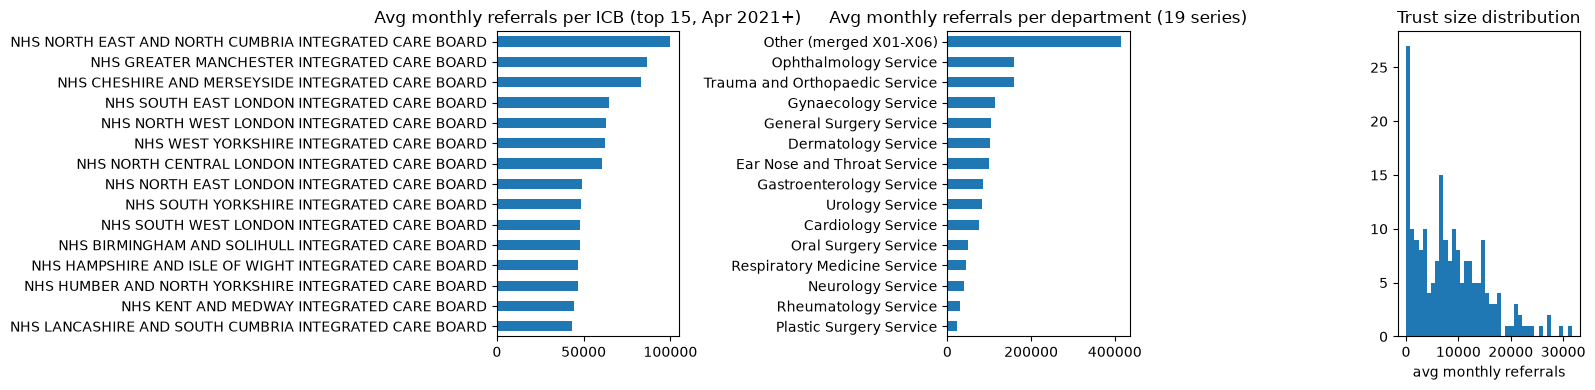

In [20]:
trust = (pub.groupby("Provider Org Code")
            .agg(months=("month", "nunique"), total_demand=("demand", "sum")).reset_index())
trust["avg_per_month"] = trust.total_demand / trust.months     # per-trust monthly mean
print(f"public providers with any demand      : {len(trust)}")
print(f"avg new referrals per trust per month : {trust.avg_per_month.mean():,.0f}")
print(trust.avg_per_month.describe().round(0).to_string())
print(f"\nlargest/smallest ratio: {trust.avg_per_month.max() / trust.avg_per_month.min():,.0f}x "
      f"— this heterogeneity is the case for per-client fine-tuning")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
icb.set_index("name").avg_per_month.head(15)[::-1].plot.barh(ax=ax[0])
ax[0].set_title("Avg monthly referrals per ICB (top 15, Apr 2021+)"); ax[0].set_ylabel("")
dept.set_index("name").avg_per_month.head(15)[::-1].plot.barh(ax=ax[1])
ax[1].set_title("Avg monthly referrals per department (19 series)"); ax[1].set_ylabel("")
ax[2].hist(trust.avg_per_month, bins=40)                       # the size distribution
ax[2].set_title("Trust size distribution"); ax[2].set_xlabel("avg monthly referrals")
plt.tight_layout()

lowest  demand month : Apr 2020  493,749
highest demand month : Mar 2026  1,932,318
trough is 30% of the 96-month median
waiting list: 4,037,223 -> 7,045,510


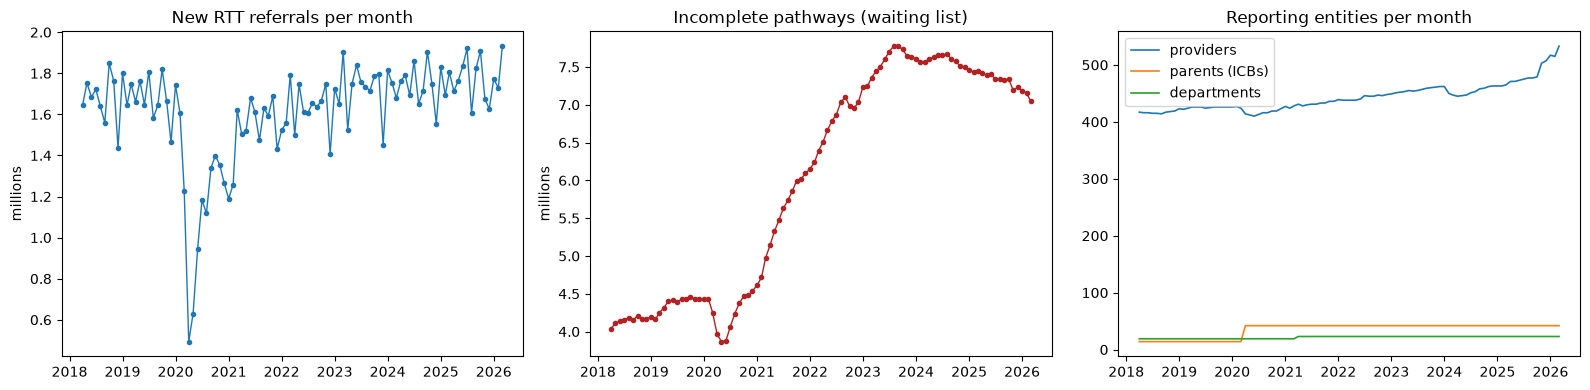

In [21]:
# national series and the COVID shock the forecaster has to survive
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(monthly.month, monthly.demand / 1e6, marker="o", ms=3, lw=1)
ax[0].set_title("New RTT referrals per month"); ax[0].set_ylabel("millions")
ax[1].plot(monthly.month, monthly.waiting / 1e6, marker="o", ms=3, lw=1, color="firebrick")
ax[1].set_title("Incomplete pathways (waiting list)"); ax[1].set_ylabel("millions")
ax[2].plot(monthly.month, monthly.providers, lw=1.2, label="providers")
ax[2].plot(monthly.month, monthly.parents, lw=1.2, label="parents (ICBs)")
ax[2].plot(monthly.month, monthly.tf_codes, lw=1.2, label="departments")
ax[2].set_title("Reporting entities per month"); ax[2].legend()
plt.tight_layout()

trough, peak = monthly.loc[monthly.demand.idxmin()], monthly.loc[monthly.demand.idxmax()]
print(f"lowest  demand month : {trough.month:%b %Y}  {trough.demand:,.0f}")
print(f"highest demand month : {peak.month:%b %Y}  {peak.demand:,.0f}")
print(f"trough is {trough.demand / monthly.demand.median() * 100:.0f}% of the 96-month median")
print(f"waiting list: {monthly.waiting.iloc[0]:,.0f} -> {monthly.waiting.iloc[-1]:,.0f}")

# H. GATE — verify the independent sector against ground truth

**Blocking.** The canonical table keeps every provider with a `sector` column, so sector filtering is a downstream one-line panel decision rather than something baked into the parquet. That is only safe if independent rows are *genuine demand* and not a reporting artefact. Four questions, answered with numbers:

- **(a)** do independents report real `Part_3` volumes with plausible dynamics, or only completed/incomplete pathways?
- **(b)** independent share over time, **per specialty** — flag any specialty where the share trends rather than holds
- **(c)** reporting behaviour: churn, months present, gaps, and how the five part types are populated
- **(d)** national totals with and without independents, so we know which published figure we reproduce

In [22]:
# (a) do independents populate Part_3, or only the completed/incomplete parts?
part_pop["sector"] = part_pop["Provider Org Code"].map(SECTOR)
pt_cols = [c for c in part_pop.columns if str(c).startswith("Part_")]      # the five part types
# share of provider-months in which each part type is non-zero, by sector
pop_rate = part_pop.groupby("sector")[pt_cols].apply(lambda g: (g > 0).mean() * 100).round(1)
print("(a) % of provider-months in which each part type is populated:")
print(pop_rate.to_string())
print()
ind_dem = prov_month[prov_month.sector == "independent"].groupby("month").demand.sum()
pub_dem = prov_month[prov_month.sector == "public"].groupby("month").demand.sum()
print(f"independent Part_3 demand: total {ind_dem.sum():,.0f}, mean {ind_dem.mean():,.0f}/month, "
      f"zero-months {int((ind_dem == 0).sum())}")
print(f"public       Part_3 demand: total {pub_dem.sum():,.0f}, mean {pub_dem.mean():,.0f}/month")
# if independents were an artefact their movements would not track the public sector
print(f"correlation of month-on-month % change, independent vs public: "
      f"{ind_dem.pct_change().corr(pub_dem.pct_change()):.3f}")

(a) % of provider-months in which each part type is populated:
RTT Part Type  Part_1A  Part_1B  Part_2  Part_2A  Part_3
sector                                                  
independent       86.1     97.0    99.8     87.2    98.3
public            85.7     99.7    99.9     84.5    99.7

independent Part_3 demand: total 11,541,248, mean 120,221/month, zero-months 0
public       Part_3 demand: total 143,908,428, mean 1,499,046/month
correlation of month-on-month % change, independent vs public: 0.943


independent share: first 6.20%, last 7.70%, min 3.94%, max 8.91%
[F-07] Independents DO report genuine Part_3 demand: 11,541,248 referrals over 96 months, 0 zero-months, share moving 6.20% -> 7.70%. Not an artefact of one part type.


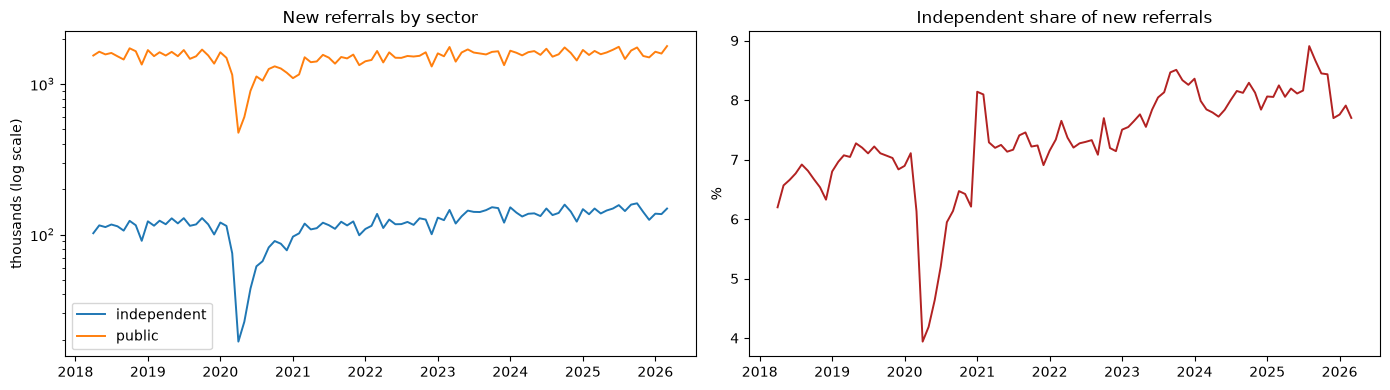

In [23]:
shr = ind_dem / (ind_dem + pub_dem) * 100                      # independent share of demand
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ind_dem.index, ind_dem / 1e3, lw=1.4, label="independent")
ax[0].plot(pub_dem.index, pub_dem / 1e3, lw=1.4, label="public")
ax[0].set_yscale("log")                                        # log: the two differ by ~10x
ax[0].set_ylabel("thousands (log scale)"); ax[0].legend()
ax[0].set_title("New referrals by sector")
ax[1].plot(shr.index, shr, lw=1.4, color="firebrick")
ax[1].set_title("Independent share of new referrals"); ax[1].set_ylabel("%")
plt.tight_layout()
print(f"independent share: first {shr.iloc[0]:.2f}%, last {shr.iloc[-1]:.2f}%, "
      f"min {shr.min():.2f}%, max {shr.max():.2f}%")
finding("F-07", f"Independents DO report genuine Part_3 demand: {ind_dem.sum():,.0f} referrals over "
                f"96 months, {int((ind_dem == 0).sum())} zero-months, share moving "
                f"{shr.iloc[0]:.2f}% -> {shr.iloc[-1]:.2f}%. Not an artefact of one part type.")

In [24]:
# (b) independent share per specialty, over time
spec["sector"] = spec["Provider Org Code"].map(SECTOR)
piv = (spec.pivot_table(index=["Treatment Function Code", "month"], columns="sector",
                        values="Total All", aggfunc="sum").fillna(0))
piv["ind_share"] = piv["independent"] / (piv["independent"] + piv["public"]) * 100
piv.to_csv(REF / "specialty_sector_month.csv")                 # cached for later phases
summ = piv.groupby(level=0).ind_share.agg(["first", "last", "mean", "max"]).round(2)
summ["change_pp"] = (summ["last"] - summ["first"]).round(2)     # percentage-point move
print("independent share of new referrals by specialty (%):")
print(summ.sort_values("change_pp", ascending=False).to_string())

independent share of new referrals by specialty (%):
                         first   last   mean    max  change_pp
Treatment Function Code                                       
C_130                     6.20  19.65  14.47  23.80      13.45
C_150                     4.84   9.33   5.28  10.56       4.49
C_330                     6.81  11.11   9.64  13.90       4.30
C_100                     6.60  10.39   8.61  12.45       3.79
X02                       0.79   2.65   1.56   5.84       1.86
X01                       3.04   4.82   4.01   5.89       1.78
C_140                     2.87   4.38   3.11   4.71       1.51
X06                      17.02  18.25  18.91  30.91       1.23
C_160                     2.33   3.51   2.87   6.19       1.18
C_120                     5.94   6.71   5.70   7.43       0.77
C_320                     0.73   1.22   0.78   1.72       0.49
C_430                     0.63   1.02   0.81   1.19       0.39
C_400                     0.61   0.60   0.65   1.47      -0.01
C_

 code  pp_per_year  first  last  TRENDING
C_130        2.201   6.20 19.65      True
C_100        0.702   6.60 10.39      True
C_330        0.672   6.81 11.11      True
C_150        0.640   4.84  9.33      True
C_110        0.391  19.37 18.99     False
  X01        0.346   3.04  4.82     False
  X02        0.261   0.79  2.65     False
C_160        0.208   2.33  3.51     False
C_140        0.189   2.87  4.38     False
C_320        0.035   0.73  1.22     False
C_430        0.026   0.63  1.02     False
C_120        0.015   5.94  6.71     False
C_340        0.007   0.89  0.71     False
C_400        0.003   0.61  0.60     False
  X05       -0.004   1.27  0.89     False
C_300       -0.055   0.86  0.26     False
C_170       -0.060   1.52  0.00     False
  X04       -0.179   0.44  0.02     False
C_101       -0.187   5.77  5.00     False
C_410       -0.237   3.51  2.79     False
C_502       -0.244   5.74  3.47     False
C_301       -0.420  11.34  8.25     False
  X03       -0.667   3.24  0.00   

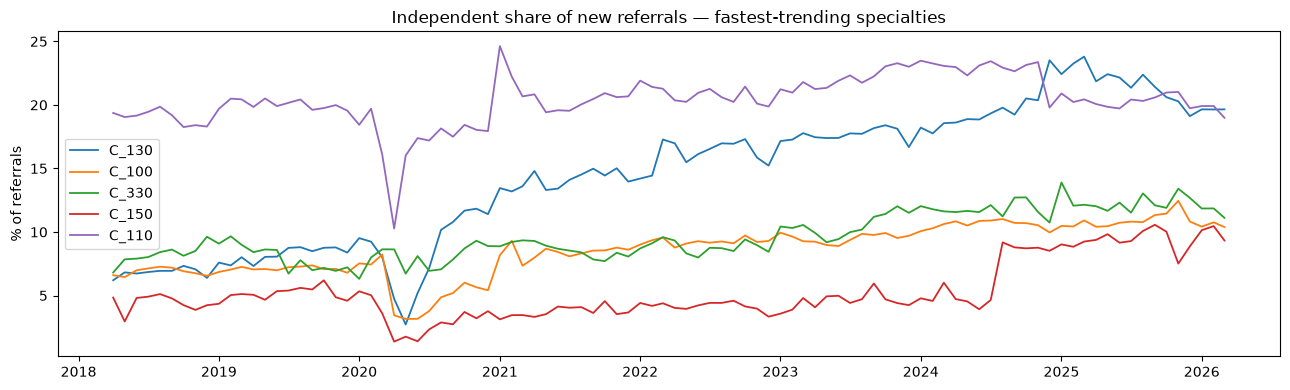

In [25]:
# flag specialties whose independent share TRENDS: slope in percentage points per year
slopes = []
for code, g in piv.groupby(level=0):                           # one specialty at a time
    s = g.reset_index()
    if s.ind_share.notna().sum() < 24 or s.ind_share.std() == 0:
        continue                                               # too little history to fit
    x = (s.month - s.month.min()).dt.days / 365.25              # years since first observation
    slope = np.polyfit(x, s.ind_share.fillna(0), 1)[0]          # linear fit, slope = pp/year
    slopes.append({"code": code, "pp_per_year": round(slope, 3),
                   "first": round(s.ind_share.iloc[0], 2), "last": round(s.ind_share.iloc[-1], 2)})
slopes = pd.DataFrame(slopes).sort_values("pp_per_year", ascending=False)
slopes["TRENDING"] = slopes.pp_per_year.abs() > 0.5             # >0.5pp/yr is drift, not noise
print(slopes.to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
for code in slopes.head(5).code:                                # five fastest-trending specialties
    s = piv.loc[code].reset_index()
    ax.plot(s.month, s.ind_share, lw=1.3, label=code)
ax.set_title("Independent share of new referrals — fastest-trending specialties")
ax.set_ylabel("% of referrals"); ax.legend()
plt.tight_layout()
finding("F-08", f"Independent share TRENDS in {int(slopes.TRENDING.sum())} of {len(slopes)} "
                f"specialties (>0.5pp/yr). Fastest: {slopes.iloc[0].code} at "
                f"{slopes.iloc[0].pp_per_year:+.2f}pp/yr ({slopes.iloc[0]['first']:.1f}% -> "
                f"{slopes.iloc[0]['last']:.1f}%). The sector mix is non-stationary, so a pooled model "
                f"must carry the sector split explicitly rather than assume a fixed composition.")

In [26]:
# (c) reporting behaviour: churn, gaps, retirement
beh = census[census.months_present > 0].copy()                  # providers that ever reported demand
beh["window_len"] = (((beh.last_month - beh.first_month).dt.days / 30.44).round() + 1).astype(int)
beh["gaps"] = beh.window_len - beh.months_present               # months absent inside its own window
print("(c) reporting behaviour by sector:")
print(beh.groupby("sector").agg(
    providers=("code", "size"),
    median_months=("months_present", "median"),
    pct_full_96=("months_present", lambda s: (s == 96).mean() * 100),   # full-window share
    median_gaps=("gaps", "median"),
    pct_with_gaps=("gaps", lambda s: (s > 0).mean() * 100),
    pct_ods_retired=("ods_retired", lambda s: s.mean() * 100),
).round(1).to_string())
print()
print("entries by year (first month seen):")
print(beh.groupby([beh.first_month.dt.year, "sector"]).size().unstack(fill_value=0).to_string())
print()
print("exits by year (last month seen, excluding those still reporting):")
gone = beh[beh.last_month < latest_month]                       # stopped before the final month
print(gone.groupby([gone.last_month.dt.year, "sector"]).size().unstack(fill_value=0).to_string())

(c) reporting behaviour by sector:
             providers  median_months  pct_full_96  median_gaps  pct_with_gaps  pct_ods_retired
sector                                                                                         
independent        451           65.0         27.9          0.0           20.8              5.8
public             196           96.0         64.3          0.0           10.7              1.5

entries by year (first month seen):
sector       independent  public
first_month                     
2018                 239     189
2019                  20       4
2020                  18       1
2021                  25       1
2022                  18       0
2023                  21       1
2024                  29       0
2025                  48       0
2026                  33       0

exits by year (last month seen, excluding those still reporting):
sector      independent  public
last_month                     
2018                  4       4
2019              

[F-09] Reporting behaviour differs sharply by sector: 64% of public providers span all 96 months vs 28% of independents. But the balanced-panel rule does NOT do the sector filtering by itself: on the demand-row definition 126 independents span all 96 months, exactly as many as the 126 public trusts. The panel is public because an explicit sector filter makes it so. What separates the sectors is obligation, not completeness: trust submission is mandatory under the NHS Standard Contract while independents are only encouraged, their returns may be filed by the commissioner on their behalf, and NHS missing-data estimates cover acute NHS providers only.


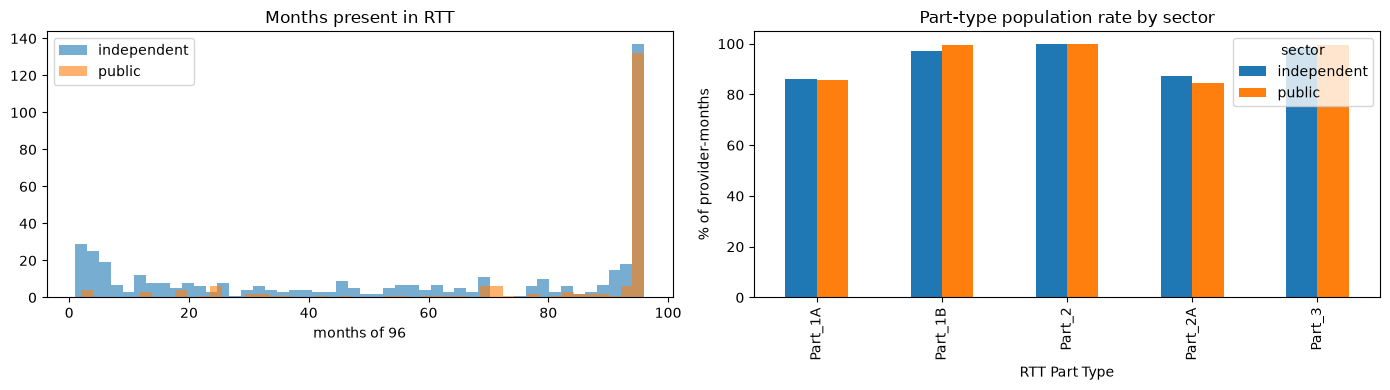

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s, g in beh.groupby("sector"):                              # overlay the two distributions
    ax[0].hist(g.months_present, bins=48, alpha=0.6, label=s)
ax[0].set_title("Months present in RTT"); ax[0].set_xlabel("months of 96"); ax[0].legend()
pop_rate.T.plot.bar(ax=ax[1])                                   # part-type population by sector
ax[1].set_title("Part-type population rate by sector"); ax[1].set_ylabel("% of provider-months")
plt.tight_layout()
finding("F-09", f"Reporting behaviour differs sharply by sector: "
                f"{beh[beh.sector == 'public'].months_present.eq(96).mean() * 100:.0f}% of public "
                f"providers span all 96 months vs "
                f"{beh[beh.sector == 'independent'].months_present.eq(96).mean() * 100:.0f}% of "
                f"independents. But the balanced-panel rule does NOT do the sector filtering "
                f"by itself: on the demand-row definition 126 independents span all 96 "
                f"months, exactly as many as the 126 public trusts. The panel is public "
                f"because an explicit sector filter makes it so. What separates the sectors "
                f"is obligation, not completeness: trust submission is mandatory under the "
                f"NHS Standard Contract while independents are only encouraged, their "
                f"returns may be filed by the commissioner on their behalf, and NHS "
                f"missing-data estimates cover acute NHS providers only.")

In [28]:
# (d) which published national figure does our table reproduce?
d2all = df[df["RTT Part Type"] == "Part_2"]                     # latest month, all rows
d2real = d2all[d2all["Treatment Function Code"] != AGG].copy()  # specialties only
d2real["sector"] = d2real["Provider Org Code"].map(SECTOR)
variants = {                                                    # four defensible bases
    "all providers, specialties only (standard published basis)": d2real["Total All"].sum(),
    "public providers only, specialties only": d2real[d2real.sector == "public"]["Total All"].sum(),
    "independents only, specialties only": d2real[d2real.sector == "independent"]["Total All"].sum(),
    "all providers INCLUDING C_999 (wrong — double counts)": d2all["Total All"].sum(),
}
print(f"England incomplete pathways, {month_of(latest.name):%B %Y} — every variant:")
for k, v in variants.items():
    print(f"  {v:>14,.0f}   {k}")
base = variants["all providers, specialties only (standard published basis)"]
print(f"\nindependents are {variants['independents only, specialties only'] / base * 100:.2f}% "
      f"of the published-basis waiting list")
finding("F-10", f"Published-basis reconciliation, {month_of(latest.name):%b %Y}: our table yields "
                f"{base:,.0f} incomplete pathways on the all-providers / specialties-only basis, of "
                f"which {variants['independents only, specialties only']:,.0f} "
                f"({variants['independents only, specialties only'] / base * 100:.2f}%) are "
                f"independent. OPEN: confirm this against the NHS England press notice for the month.")

England incomplete pathways, March 2026 — every variant:
       7,045,510   all providers, specialties only (standard published basis)
       6,603,854   public providers only, specialties only
         441,656   independents only, specialties only
      14,091,020   all providers INCLUDING C_999 (wrong — double counts)

independents are 6.27% of the published-basis waiting list
[F-10] Published-basis reconciliation, Mar 2026: our table yields 7,045,510 incomplete pathways on the all-providers / specialties-only basis, of which 441,656 (6.27%) are independent. OPEN: confirm this against the NHS England press notice for the month.


# I. KH03 overnight beds

In [29]:
print(f"workbooks: {len(kh)}   total {sum(f.stat().st_size for f in kh) / 1e6:.1f} MB")
print("extensions:", dict(collections.Counter(f.suffix.lower() for f in kh)))   # xls vs xlsx mix
print("earliest by name:", kh[0].name)
print("latest by name  :", kh[-1].name)

workbooks: 61   total 11.0 MB
extensions: {'.xlsx': 50, '.xls': 11}
earliest by name: 1920-Q1-Beds-Open-Overnight-Web_File-Final-DE5WC.xlsx
latest by name  : Beds-Open-Overnight-Web_File-Q4-2025-26.xlsx


# J. Column dossier — what every column is, and whether the goal needs it

Everything so far has treated the RTT return as a source of rows. This section treats it as a source of **columns**, and asks of each one: what is it, is it populated, is it a fact or a label for a fact we already have, and does anything in the README's system consume it.

The keep/drop decision itself belongs to `03_data_processing.ipynb`, which is where transformation lives. This section only supplies the measurements it decides on.

Three tests, in order of how much they settle:

1. **Is it populated?** A column that is blank, constant, or a rounding-error fraction of the total decides nothing.
2. **Is it a label or an axis?** If a column takes exactly one value for every `provider × treatment function × part type` row, it is *functionally determined* by keys we already carry — a label, and F-11 showed labels are unstable while codes are not. If it takes several values, it is a genuine extra dimension, and collapsing it discards real information that has to be justified rather than waved away.
3. **Does the goal consume it?** The README names a specific state vector: demand in, throughput out, backlog, the bed-linked admission queue, the 18-week breach count, and the trust → ICB → national hierarchy. A column outside that is not a feature, however interesting.

In [30]:
# One file per era, read in full — this is the one place every column is actually looked at.
# `low_memory=False` makes pandas read the whole column before choosing a dtype, which stops
# mixed-type columns being guessed inconsistently between chunks.
dossier = []
for era, p in [("pre-2021", csvs[0]), ("post-2021", csvs[-1])]:
    d = pd.read_csv(p, low_memory=False)
    band = [c for c in d.columns if "Weeks SUM" in c]           # the waiting-time histogram
    for c in d.columns:
        s = d[c]
        dossier.append({"era": era, "column": "<%d band columns>" % len(band) if c in band else c,
                        "is_band": c in band,
                        "filled_pct": round(s.notna().mean() * 100, 1),
                        "distinct": s.nunique(),
                        "example": str(s.dropna().iloc[0])[:30] if s.notna().any() else ""})

dos = pd.DataFrame(dossier)
# collapse the band columns into one summary row per era: 53 or 105 near-identical columns
# printed individually would bury the 16 that carry meaning
bands = (dos[dos.is_band].groupby("era")
            .agg(column=("column", "first"), filled_pct=("filled_pct", "mean"),
                 distinct=("distinct", "mean"), example=("example", "first")).reset_index())
bands["is_band"] = True
shown = pd.concat([dos[~dos.is_band], bands.round(1)], ignore_index=True)
for era in ["pre-2021", "post-2021"]:
    print(f"=== {era}")
    print(shown[shown.era == era].drop(columns=["era", "is_band"]).to_string(index=False))
    print()

=== pre-2021
                                column  filled_pct  distinct                        example
                                Period       100.0       1.0                 RTT-April-2018
              Provider Parent Org Code       100.0      14.0                            Q71
                  Provider Parent Name       100.0      14.0             NHS ENGLAND LONDON
                     Provider Org Code       100.0     417.0                            NQV
                     Provider Org Name       100.0     417.0             BROMLEY HEALTHCARE
          Commissioner Parent Org Code        96.2      14.0                            Q71
              Commissioner Parent Name        96.2      14.0             NHS ENGLAND LONDON
                 Commissioner Org Code       100.0     197.0                            07Q
                 Commissioner Org Name        98.7     196.0                NHS BROMLEY CCG
                         RTT Part Type       100.0       5.0       

## Label or axis?

The canonical key is `provider × department × month`, with the part type pivoted into columns. Any column that takes exactly one value within a `provider × treatment function × part type` group is determined by that key — dropping it loses nothing that a join cannot restore. Any column that takes several is a dimension the build is **summing over**, and that is a decision, not a tidy-up.

`nunique()` per group answers this directly: a maximum of 1 means label, more than 1 means axis.

In [31]:
d = pd.read_csv(csvs[-1], low_memory=False)                    # the richest schema
d = d[d["Treatment Function Code"] != AGG]                     # aggregate rows are not data
KEY = ["Provider Org Code", "Treatment Function Code", "RTT Part Type"]
descriptive = [c for c in d.columns if "Weeks SUM" not in c]   # the 16 non-band columns
# Three of those 16 are MEASURES, not descriptions. The label-or-axis test only makes sense for a
# description: a measure obviously varies inside a key holding several commissioner rows.
MEASURES = ["Total", "Total All", "Patients with unknown clock start date"]

rows = []
for c in descriptive:
    if c in MEASURES:                                          # measured, not described
        rows.append({"column": c, "max_values_per_key": int(d.groupby(KEY)[c].nunique().max()),
                     "verdict": "MEASURE - the test does not apply"})
        continue
    if c in KEY:
        rows.append({"column": c, "max_values_per_key": 1, "verdict": "KEY"})
        continue
    n = d.groupby(KEY)[c].nunique(dropna=False).max()          # values per key row
    rows.append({"column": c, "max_values_per_key": int(n),
                 "verdict": "label — determined by the key" if n <= 1
                            else "AXIS — the build sums over this"})
print(pd.DataFrame(rows).to_string(index=False))

axes = [r["column"] for r in rows if r["verdict"].startswith("AXIS")]
finding("F-21", f"Of the {len(descriptive)} descriptive columns, every one is either a key or a "
                f"label determined by the key, EXCEPT {len(axes)}: {axes}. (The three measure "
                f"columns are excluded from this test: a measure varies inside a key "
                f"holding several commissioner rows by definition, so counting them as "
                f"axes is a category error.) The commissioner "
                f"columns are the only genuine second dimension in the return — who paid, as "
                f"opposed to who delivered. Collapsing them is a deliberate loss of information, "
                f"not the removal of redundancy, and needs the justification below.")

                                column  max_values_per_key                           verdict
                                Period                   1     label — determined by the key
              Provider Parent Org Code                   1     label — determined by the key
                  Provider Parent Name                   1     label — determined by the key
                     Provider Org Code                   1                               KEY
                     Provider Org Name                   1     label — determined by the key
          Commissioner Parent Org Code                  43   AXIS — the build sums over this
              Commissioner Parent Name                  43   AXIS — the build sums over this
                 Commissioner Org Code                 104   AXIS — the build sums over this
                 Commissioner Org Name                 104   AXIS — the build sums over this
                         RTT Part Type                   1            

## The commissioner axis is the only real thing being discarded — so how much does it matter?

The README escalates **trust → ICB → national**: an ICB board is asked to approve capacity for services delivered by trusts in its own footprint. That design is only sound if an ICB actually commissions the demand flowing through those trusts. If a large share of a trust's referrals are paid for by *other* ICBs, the board is being asked to fund activity it does not control, and the escalation tier is wrong.

The RTT file can answer this directly, because it carries both the provider's parent and the commissioner's parent. This is the measurement that decides whether the commissioner columns can be dropped — not their fill rate.

In [32]:
dem = d[d["RTT Part Type"] == "Part_3"].copy()                 # new referrals only
dem["in_icb"] = dem["Commissioner Parent Org Code"] == dem["Provider Parent Org Code"]
overall = dem[dem.in_icb]["Total All"].sum() / dem["Total All"].sum() * 100

# per provider, so the headline is not carried by a few very large trusts
per_prov = (dem.groupby("Provider Org Code")
               .apply(lambda g: g[g.in_icb]["Total All"].sum() / g["Total All"].sum() * 100,
                      include_groups=False)                    # exclude the key from the lambda
               .rename("in_icb_pct"))
pub_prov = per_prov[per_prov.index.map(SECTOR) == "public"]    # trusts only — they are the clients

print(f"share of all new referrals commissioned within the provider's own ICB : {overall:.1f}%")
print()
print("per public provider, that same share:")
print(pub_prov.describe().round(1).to_string())
print(f"\nproviders below 50% in-ICB: {int((pub_prov < 50).sum())} of {len(pub_prov)}")

finding("F-22", f"{overall:.1f}% of new referrals are commissioned by an organisation under the "
                f"same parent as the provider delivering them; per public provider the median is "
                f"{pub_prov.median():.1f}% and {int((pub_prov < 50).sum())} of {len(pub_prov)} sit "
                f"below 50%. The trust -> ICB escalation tier is therefore sound for the typical "
                f"trust but NOT universal: a board approving capacity at a low-in-ICB trust is "
                f"partly funding activity commissioned elsewhere. Recorded as a known limitation "
                f"of the hierarchy, and the reason the commissioner columns can be collapsed for "
                f"the forecaster without the caveat being forgotten.")

share of all new referrals commissioned within the provider's own ICB : 84.3%

per public provider, that same share:
count    150.0
mean      84.4
std       19.8
min        0.1
25%       81.3
50%       91.9
75%       97.7
max      100.0

providers below 50% in-ICB: 11 of 150
[F-22] 84.3% of new referrals are commissioned by an organisation under the same parent as the provider delivering them; per public provider the median is 91.9% and 11 of 150 sit below 50%. The trust -> ICB escalation tier is therefore sound for the typical trust but NOT universal: a board approving capacity at a low-in-ICB trust is partly funding activity commissioned elsewhere. Recorded as a known limitation of the hierarchy, and the reason the commissioner columns can be collapsed for the forecaster without the caveat being forgotten.


## What the numeric columns actually contain

Three headline columns and a wide band histogram. Which of them carry a number depends on the part type, and that dependency is what determines whether a column can serve as a feature at all.

In [33]:
band = [c for c in d.columns if "Weeks SUM" in c]              # this era's histogram
d[band] = d[band].fillna(0)                                    # blank band = no patients
num = d.groupby("RTT Part Type").agg(
    Total=("Total", "sum"),                                    # blank for some part types?
    Total_All=("Total All", "sum"),                            # the headline we actually read
    unknown_start=("Patients with unknown clock start date", "sum"))
num["band_sum"] = d[band].sum(axis=1).groupby(d["RTT Part Type"]).sum()
num["bands/TotalAll"] = (num.band_sum / num.Total_All).round(4)     # 0 = no bands for this part
num["Total/TotalAll"] = (num.Total / num.Total_All).round(4)        # 0 = column is empty here
print(num.to_string(float_format=lambda v: f"{v:,.0f}"))

unk_pct = 100 * num.unknown_start.sum() / num.Total_All.sum()
empty_for = num.index[num.Total.eq(0)].tolist()
finding("F-23", f"'Total All' is the only headline column populated for all five part types: "
                f"'Total' is identically zero for {empty_for} and equals 'Total All' minus the "
                f"unknown-clock-start count for the rest. That count is {unk_pct:.4f}% of all "
                f"activity and is already inside 'Total All'. The waiting-time bands sum to "
                f"'Total All' exactly for Part_2 and Part_2A, to 0.999x for the completed parts "
                f"(the unknown-start patients are unbanded), and to zero for Part_3 — confirming "
                f"F-03 on the full column set rather than by inspection of one part type.")

                  Total  Total_All  unknown_start  band_sum  bands/TotalAll  Total/TotalAll
RTT Part Type                                                                              
Part_1A         320,415     320541            126   320,415               1               1
Part_1B       1,374,620    1375272            652 1,374,620               1               1
Part_2                0    7045510              0 7,045,510               1               0
Part_2A               0    1178492              0 1,178,492               1               0
Part_3                0    1932318              0         0               0               0
[F-23] 'Total All' is the only headline column populated for all five part types: 'Total' is identically zero for ['Part_2', 'Part_2A', 'Part_3'] and equals 'Total All' minus the unknown-clock-start count for the rest. That count is 0.0066% of all activity and is already inside 'Total All'. The waiting-time bands sum to 'Total All' exactly for Part_2 and

# K. Findings summary, then delete the archives


## K. Format drift across eight years

The files span April 2018 to March 2026 and were not produced by one unchanging pipeline. This section
looks for the drift that would corrupt a join or a parse **silently**, as opposed to the schema break
already recorded in F-02, which is loud.

Seven surfaces are checked: byte-order marks, header spelling, column counts, the `Period` string, line
endings, the join keys, and the numeric formats. Each is the kind of thing that costs a day when it is
found late and nothing when it is found here.

In [34]:
# --- 1. byte order mark: a UTF-8 BOM turns the first header into '﻿Period' and breaks the join
bom = [p.name for p in csvs if open(p, "rb").read(3) == bytes((0xEF, 0xBB, 0xBF))]

# --- 2. header spelling. Normalise whitespace and case, then ask if one column ever had two spellings
tidy = lambda c: re.sub(r"\s+", " ", c).strip().lower()
spellings = collections.defaultdict(set)
for h in headers.values():
    for c in h:
        spellings[tidy(c)].add(c)
drift = {k: v for k, v in spellings.items() if len(v) > 1}
padded = {c for h in headers.values() for c in h if c != c.strip()}

# --- 3. Period string. Mask the digits so only the SHAPE of the string is compared
shapes = collections.Counter(
    re.sub(r"\d", "#", pd.read_csv(p, usecols=["Period"], nrows=1, dtype=str).iat[0, 0]) for p in csvs)

# --- 4. line endings. Harmless to pandas, but it evidences a change of producing system
eol = collections.Counter("CRLF" if b"\r\n" in open(p, "rb").read(200_000) else "LF" for p in csvs)

print(f"BOM present            : {len(bom)} of {len(csvs)} files")
print(f"header spelling drift  : {len(drift)} columns with more than one raw spelling")
print(f"headers with padding   : {len(padded)}")
print(f"column counts          : {dict(collections.Counter(len(h) for h in headers.values()))}")
print(f"line endings           : {dict(eol)}")
print(f"Period string shapes   : {len(shapes)} distinct")
for shape, n in sorted(shapes.items(), key=lambda kv: -kv[1])[:4]:
    print(f"    {shape!r}: {n} files")


BOM present            : 0 of 96 files
header spelling drift  : 0 columns with more than one raw spelling
headers with padding   : 0
column counts          : {69: 36, 121: 60}
line endings           : {'LF': 36, 'CRLF': 60}
Period string shapes   : 24 distinct
    'RTT-JULY-####': 5 files
    'RTT-AUGUST-####': 5 files
    'RTT-SEPTEMBER-####': 5 files
    'RTT-OCTOBER-####': 5 files


In [35]:
# --- 5. the join keys and the headline measure, read as TEXT so pandas cannot hide a format problem
#        by silently coercing it. dtype=str keeps '007' and ' 007 ' distinguishable; keep_default_na
#        keeps a blank cell as '' rather than NaN, which is the distinction being tested.
part_types, key_dirty, nonnumeric = collections.Counter(), collections.Counter(), set()
blanks = negatives = 0
for p in csvs:
    d = pd.read_csv(p, usecols=["Provider Org Code", "Treatment Function Code", "RTT Part Type",
                                "Total All"], dtype=str, low_memory=False, keep_default_na=False)
    part_types.update(d["RTT Part Type"].unique())
    for col in ["Provider Org Code", "Treatment Function Code"]:
        v = d[col]
        if (v != v.str.strip()).any(): key_dirty[f"{col}: padding"] += 1
        if (v != v.str.upper()).any(): key_dirty[f"{col}: case"] += 1
    t = d["Total All"]
    blanks += int((t == "").sum())
    negatives += int(t.str.fullmatch(r"-\d+").sum())
    nonnumeric |= set(t[~t.str.fullmatch(r"-?\d+(\.\d+)?") & (t != "")].unique()[:5])

print(f"RTT part types across all {len(csvs)} months: {dict(part_types)}")
print(f"join-key padding or case problems         : {dict(key_dirty) or 'none, all 96 clean'}")
print(f"Total All - blanks {blanks:,} | negatives {negatives:,} | non-numeric {nonnumeric or 'none'}")

# These three are what a silent format change would break, so they are asserts rather than prints.
assert not key_dirty, "a join key carries padding or mixed case in some month"
assert not nonnumeric, "Total All holds a value that is not a plain number"
assert set(part_types) == {"Part_1A", "Part_1B", "Part_2", "Part_2A", "Part_3"}, "part type vocabulary drifted"

# The Period drift is survivable only because month_of() upper-cases before matching, so the same
# parser cancels the case on both sides. That protection was incidental, not designed, and nothing
# recorded it - so it is now a test. Remove the .upper() and this fires immediately, instead of the
# Period check silently failing on roughly half the window.
assert month_of("RTT-April-2019") == month_of("RTT-APRIL-2019"), (
    "month_of() is case-sensitive: the Period column changes case mid-window, so the A3 check "
    "would report false mismatches on every month of the other era")

finding("F-41", f"Format drift audit: 0 BOMs, 0 header spelling variants, 0 padded headers, join keys "
                f"clean in all {len(csvs)} months, Total All numeric everywhere with no blanks or "
                f"negatives, part types stable. Real drift found in two places, both benign: the "
                f"Period string changes case mid-window ({len(shapes)} shapes, 'RTT-April-2018' vs "
                f"'RTT-APRIL-2021') and line endings switch {dict(eol)} at the same Apr-2021 break. "
                f"The Period drift is neutralised only because month_of() upper-cases before matching "
                f"- do not remove that .upper(), it is load-bearing.")


RTT part types across all 96 months: {'Part_1A': 96, 'Part_1B': 96, 'Part_2': 96, 'Part_2A': 96, 'Part_3': 96}
join-key padding or case problems         : none, all 96 clean
Total All - blanks 0 | negatives 0 | non-numeric none
[F-41] Format drift audit: 0 BOMs, 0 header spelling variants, 0 padded headers, join keys clean in all 96 months, Total All numeric everywhere with no blanks or negatives, part types stable. Real drift found in two places, both benign: the Period string changes case mid-window (24 shapes, 'RTT-April-2018' vs 'RTT-APRIL-2021') and line endings switch {'LF': 36, 'CRLF': 60} at the same Apr-2021 break. The Period drift is neutralised only because month_of() upper-cases before matching - do not remove that .upper(), it is load-bearing.


In [36]:
# --- 6. band columns: a blank is not a zero until we decide it is, and the blank RATE moves with the
#        schema break. This is why the build calls .fillna(0) on bands rather than trusting the parse.
for label, p in [("2018-04 first", csvs[0]), ("2021-03 pre-break", csvs[35]),
                 ("2021-04 post-break", csvs[36]), ("2026-03 last", csvs[-1])]:
    d = pd.read_csv(p, dtype=str, low_memory=False, keep_default_na=False)
    bands = [c for c in d.columns if "Weeks SUM" in c]
    cells = d[bands].to_numpy().ravel()
    blank = (cells == "").sum()
    print(f"  {label:20s} {len(bands):3d} bands | blank {blank:9,d} of {len(cells):11,d} "
          f"({blank / len(cells) * 100:4.1f}%)")

print("\nA blank band cell means no patients waited that long, so filling it with 0 is correct - but")
print("it is a decision, and the rate jumping at the break is the schema change showing up again.")


  2018-04 first         53 bands | blank 2,377,340 of  10,406,020 (22.8%)


  2021-03 pre-break     53 bands | blank 1,940,118 of   9,135,610 (21.2%)


  2021-04 post-break   105 bands | blank 6,130,042 of  16,826,355 (36.4%)


  2026-03 last         105 bands | blank 5,886,910 of  19,339,320 (30.4%)

A blank band cell means no patients waited that long, so filling it with 0 is correct - but
it is a decision, and the rate jumping at the break is the schema change showing up again.


In [37]:
print(f"{len(findings)} findings recorded in this run:\n")
for fid, text in findings:                                      # everything established above
    print(f"[{fid}] {text}\n")
pd.DataFrame(findings, columns=["id", "finding"]).to_csv(REF / "findings.csv", index=False)

18 findings recorded in this run:

[F-01] Integrity PASS=True. 96/96 months present and structurally sound; archives CRC-clean (0 tested); extraction sizes exact; no Period/filename mismatches; no truncated rows; all 61 KH03 workbooks valid; no duplicate provider codes in the reference.

[F-02] Schema break at Apr 2021: 69 columns for 36 months, then 121 for 60. The single ['Gt 52 Weeks SUM 1'] column is replaced by 53 weekly bands running to 104w. The 52 bands below 52w are identical across both eras, so any >18w metric is era-stable and only the >52 tail differs. Handling rule belongs to 03_data_processing.ipynb, not here.

[F-03] Part_3 (new referrals) has NO populated week bands, by design: a new referral has waited ~0 weeks, so bands are meaningless for it. Demand = 'Total All' alone. Bands only ever feed the backlog / agentic side. Expected, not a defect — do not 'fix'.

[F-04] C_999 is an EXACT aggregate, verified across all 96 months x 5 part types x every provider (199,410 gro

In [38]:
# the csvs are the only copy needed now, and section A verified them against these archives
freed = sum(z.stat().st_size for z in zips)                     # bytes about to be reclaimed
for z in zips:
    z.unlink()                                                  # delete each archive
if RTT_ZIPS.exists() and not any(RTT_ZIPS.iterdir()):
    RTT_ZIPS.rmdir()                                            # remove the now-empty folder
print(f"deleted {len(zips)} archives, freed {freed / 1e6:.0f} MB")
print("csvs still on disk:", len(list(RTT_CSV.glob('*.csv'))))

deleted 0 archives, freed 0 MB
csvs still on disk: 96
